In [ ]:

!pip install -q datasets scikit-learn joblib pandas matplotlib seaborn


In [ ]:

from datasets import load_dataset

print("Downloading TweetEval dataset...")

dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

train_data = dataset["train"]
validation_data = dataset["validation"]
test_data = dataset["test"]

print("Dataset downloaded successfully!")
print("Training samples:", len(train_data))
print("Validation samples:", len(validation_data))
print("Testing samples:", len(test_data))


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset downloaded successfully!
Training samples: 45615
Validation samples: 2000
Testing samples: 12284


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X_train = train_data["text"]
y_train = train_data["label"]

X_valid = validation_data["text"]
y_valid = validation_data["label"]

X_test = test_data["text"]
y_test = test_data["label"]

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=2.0
    ))
])

print("Training started...")

model.fit(X_train, y_train)

print("Training completed successfully!")


Training started...
Training completed successfully!


VALIDATION ACCURACY:
0.682

VALIDATION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative       0.61      0.41      0.49       312
     Neutral       0.65      0.75      0.69       869
    Positive       0.74      0.72      0.73       819

    accuracy                           0.68      2000
   macro avg       0.67      0.62      0.64      2000
weighted avg       0.68      0.68      0.68      2000


TEST ACCURACY:
0.5940247476392054

TEST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative       0.67      0.39      0.50      3972
     Neutral       0.60      0.72      0.65      5937
    Positive       0.52      0.61      0.56      2375

    accuracy                           0.59     12284
   macro avg       0.60      0.58      0.57     12284
weighted avg       0.61      0.59      0.59     12284



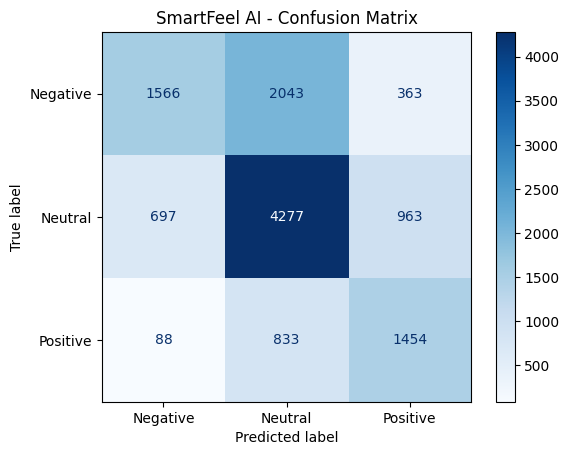

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

# Validation results
valid_predictions = model.predict(X_valid)

print("VALIDATION ACCURACY:")
print(accuracy_score(y_valid, valid_predictions))

print("\nVALIDATION CLASSIFICATION REPORT:")
print(classification_report(
    y_valid,
    valid_predictions,
    target_names=labels,
    zero_division=0
))

# Final test evaluation
test_predictions = model.predict(X_test)

print("\nTEST ACCURACY:")
print(accuracy_score(y_test, test_predictions))

print("\nTEST CLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=labels,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=labels,
    cmap="Blues"
)

plt.title("SmartFeel AI - Confusion Matrix")
plt.show()


In [ ]:

import joblib

joblib.dump(model, "smartfeel_sentiment_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

from google.colab import files

files.download("smartfeel_sentiment_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q transformers datasets accelerate evaluate


In [ ]:

from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

print("RoBERTa model loaded successfully!")
print(roberta_model.config.id2label)


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RoBERTa model loaded successfully!
{0: 'negative', 1: 'neutral', 2: 'positive'}


In [ ]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
roberta_model.to(device)

def analyze_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = roberta_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)[0]

    result = {
        roberta_model.config.id2label[i]: round(
            probabilities[i].item() * 100, 2
        )
        for i in range(len(probabilities))
    }

    return result

print(analyze_sentiment("I really love this product!"))
print(analyze_sentiment("This is the worst experience ever."))
print(analyze_sentiment("The product arrived yesterday."))


{'negative': 0.5, 'neutral': 1.05, 'positive': 98.44}
{'negative': 94.53, 'neutral': 4.57, 'positive': 0.9}
{'negative': 0.35, 'neutral': 43.07, 'positive': 56.57}


In [ ]:

print("===== GPU INFORMATION =====")

!nvidia-smi

print("\n===== MODEL LABELS =====")
print(roberta_model.config.id2label)

print("\n===== BASELINE TEST ACCURACY =====")
print(accuracy_score(y_test, test_predictions))

print("\n===== ROBERTA TEST RESULTS =====")
print(analyze_sentiment("I really love this product!"))
print(analyze_sentiment("This is the worst experience ever."))
print(analyze_sentiment("The product arrived yesterday."))


===== GPU INFORMATION =====
Tue Nov 17 05:46:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P0             33W /   70W |    3787MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-------------------

In [ ]:

import torch
import gc

# Remove the previous pretrained model from GPU memory
if "roberta_model" in globals():
    del roberta_model

gc.collect()
torch.cuda.empty_cache()

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory cleared!")


GPU: Tesla T4
GPU memory cleared!


In [ ]:

from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "cardiffnlp/twitter-roberta-base"

id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("SmartFeel RoBERTa model is ready!")
print("Device:", device)


config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

SmartFeel RoBERTa model is ready!
Device: cuda


In [ ]:

from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 16

class SentimentDataset(Dataset):

    def __init__(self, data):
        self.texts = data["text"]
        self.labels = data["label"]

        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return item


train_dataset = SentimentDataset(train_data)
validation_dataset = SentimentDataset(validation_data)
test_dataset = SentimentDataset(test_data)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(validation_dataset))
print("Testing dataset:", len(test_dataset))


ValueError: text input must be of type `str` (single example), `list[str]` (batch or single pretokenized example) or `list[list[str]]` (batch of pretokenized examples) or `list[tuple[list[str], list[str]]]` (batch of pretokenized sequence pairs).

In [ ]:

print("Dataset loaded:", "dataset" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())
print("Training data loaded:", "train_data" in globals())

print("\nDataset columns:")
print(train_data.column_names)

print("\nFirst training example:")
print(train_data[0])


Dataset loaded: True
Tokenizer loaded: True
Training data loaded: True

Dataset columns:
['text', 'label']

First training example:
{'text': '"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"', 'label': 2}


In [ ]:

from torch.utils.data import Dataset, DataLoader
import torch

MAX_LENGTH = 128
BATCH_SIZE = 16

class SentimentDataset(Dataset):

    def __init__(self, data, tokenizer):
        self.texts = data["text"]
        self.labels = data["label"]

        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        return {
            "input_ids": torch.tensor(
                self.encodings["input_ids"][index],
                dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                self.encodings["attention_mask"][index],
                dtype=torch.long
            ),
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }


train_dataset = SentimentDataset(train_data, tokenizer)
validation_dataset = SentimentDataset(validation_data, tokenizer)
test_dataset = SentimentDataset(test_data, tokenizer)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

print("Dataset preparation successful!")
print("Training:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Testing:", len(test_dataset))


ValueError: text input must be of type `str` (single example), `list[str]` (batch or single pretokenized example) or `list[list[str]]` (batch of pretokenized examples) or `list[tuple[list[str], list[str]]]` (batch of pretokenized sequence pairs).

In [ ]:

print("Checking SmartFeel AI environment...")

for name in ["torch", "tokenizer", "train_data",
             "validation_data", "test_data"]:
    print(name, "EXISTS" if name in globals() else "MISSING")

if "train_data" in globals():
    print("\nTraining dataset:")
    print(train_data)

    print("\nFirst example:")
    print(train_data[0])

if "tokenizer" in globals():
    print("\nTokenizer:")
    print(tokenizer.name_or_path)


Checking SmartFeel AI environment...
torch EXISTS
tokenizer EXISTS
train_data EXISTS
validation_data EXISTS
test_data EXISTS

Training dataset:
Dataset({
    features: ['text', 'label'],
    num_rows: 45615
})

First example:
{'text': '"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"', 'label': 2}

Tokenizer:
cardiffnlp/twitter-roberta-base


In [ ]:

from transformers import DataCollatorWithPadding
from torch.utils.data import DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 16

print("Tokenizing training dataset...")

def tokenize_function(examples):
    result = tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

    result["labels"] = examples["label"]
    return result


# Tokenize the three datasets in batches
tokenized_train = train_data.map(
    tokenize_function,
    batched=True,
    remove_columns=train_data.column_names
)

print("Training dataset completed!")

tokenized_validation = validation_data.map(
    tokenize_function,
    batched=True,
    remove_columns=validation_data.column_names
)

print("Validation dataset completed!")

tokenized_test = test_data.map(
    tokenize_function,
    batched=True,
    remove_columns=test_data.column_names
)

print("Testing dataset completed!")


# Automatically pad each batch
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)


# Create DataLoaders
train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    collate_fn=data_collator
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    collate_fn=data_collator
)

print("\n===== DATASET PREPARATION COMPLETE =====")
print("Training samples:", len(tokenized_train))
print("Validation samples:", len(tokenized_validation))
print("Testing samples:", len(tokenized_test))


Tokenizing training dataset...


NameError: name 'train_data' is not defined

In [ ]:

from datasets import load_dataset

print("Loading TweetEval dataset...")

dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

train_data = dataset["train"]
validation_data = dataset["validation"]
test_data = dataset["test"]

print("Dataset loaded successfully!")
print("Training:", len(train_data))
print("Validation:", len(validation_data))
print("Testing:", len(test_data))


Loading TweetEval dataset...


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Training: 45615
Validation: 2000
Testing: 12284


In [ ]:

import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 3

best_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(**batch)

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

        total_loss += loss.item()

        progress.set_postfix(
            loss=round(loss.item(), 4)
        )

    # Validation
    model.eval()

    predictions = []
    actual_labels = []

    with torch.no_grad():

        for batch in validation_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            preds = torch.argmax(
                outputs.logits, dim=1
            )

            predictions.extend(preds.cpu().tolist())
            actual_labels.extend(
                batch["labels"].cpu().tolist()
            )

    accuracy = accuracy_score(
        actual_labels, predictions
    )

    macro_f1 = f1_score(
        actual_labels,
        predictions,
        average="macro"
    )

    print(f"\nEpoch {epoch + 1}")
    print("Average Training Loss:", round(
        total_loss / len(train_loader), 4
    ))
    print("Validation Accuracy:", round(accuracy, 4))
    print("Validation Macro F1:", round(macro_f1, 4))

    if macro_f1 > best_f1:

        best_f1 = macro_f1

        model.save_pretrained(
            "/content/smartfeel_roberta_finetuned"
        )

        tokenizer.save_pretrained(
            "/content/smartfeel_roberta_finetuned"
        )

        print("Best model saved!")

print("\nSMARTFEEL AI TRAINING COMPLETED!")


NameError: name 'model' is not defined

In [ ]:

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.optim import AdamW

MODEL_NAME = "cardiffnlp/twitter-roberta-base"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Create a new 3-class classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

# Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

# Create optimizer
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

print("RoBERTa model created successfully!")
print("Device:", device)
print("Labels:", model.config.id2label)


config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

RoBERTa model created successfully!
Device: cuda
Labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:

print("MODEL:", "model" in globals())
print("OPTIMIZER:", "optimizer" in globals())
print("TRAIN LOADER:", "train_loader" in globals())
print("VALIDATION LOADER:", "validation_loader" in globals())
print("DEVICE:", device)

print("\nReady to train SmartFeel AI!")


MODEL: True
OPTIMIZER: True
TRAIN LOADER: False
VALIDATION LOADER: False
DEVICE: cuda

Ready to train SmartFeel AI!


In [ ]:

from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

BATCH_SIZE = 16

# Dynamic padding
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

# Training DataLoader
train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

# Validation DataLoader
validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

# Testing DataLoader
test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

print("All DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


NameError: name 'tokenized_train' is not defined

In [ ]:

from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# 1. Make sure the original dataset exists
if "train_data" not in globals():
    dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    train_data = dataset["train"]
    validation_data = dataset["validation"]
    test_data = dataset["test"]

# 2. Make sure tokenizer exists
if "tokenizer" not in globals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        "cardiffnlp/twitter-roberta-base"
    )

# 3. Tokenization function
def tokenize_function(examples):
    result = tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )
    result["labels"] = examples["label"]
    return result

# 4. Tokenize datasets
print("Tokenizing training data...")

tokenized_train = train_data.map(
    tokenize_function,
    batched=True,
    remove_columns=train_data.column_names
)

print("Tokenizing validation data...")

tokenized_validation = validation_data.map(
    tokenize_function,
    batched=True,
    remove_columns=validation_data.column_names
)

print("Tokenizing test data...")

tokenized_test = test_data.map(
    tokenize_function,
    batched=True,
    remove_columns=test_data.column_names
)

# 5. Create DataLoaders
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

BATCH_SIZE = 16

train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    collate_fn=data_collator
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    collate_fn=data_collator
)

print("\n===== SUCCESS =====")
print("Training samples:", len(tokenized_train))
print("Validation samples:", len(tokenized_validation))
print("Testing samples:", len(tokenized_test))
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


Tokenizing training data...


Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Tokenizing validation data...


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing test data...


Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

In [ ]:

print("Training tokenized:", "tokenized_train" in globals())
print("Validation tokenized:", "tokenized_validation" in globals())
print("Test tokenized:", "tokenized_test" in globals())

print("Model:", "model" in globals())
print("Optimizer:", "optimizer" in globals())


Training tokenized: True
Validation tokenized: True
Test tokenized: True
Model: True
Optimizer: True


In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

train_loader = DataLoader(
    tokenized_train,
    batch_size=16,
    shuffle=True,
    collate_fn=data_collator
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=16,
    shuffle=False,
    collate_fn=data_collator
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=16,
    shuffle=False,
    collate_fn=data_collator
)

print("All DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

All DataLoaders created successfully!
Training batches: 2851
Validation batches: 125
Test batches: 768


In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
import torch

EPOCHS = 1

model.train()
total_loss = 0

progress = tqdm(train_loader, desc="Training RoBERTa")

for batch in progress:
    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    optimizer.zero_grad()

    outputs = model(**batch)
    loss = outputs.loss

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )

    optimizer.step()

    total_loss += loss.item()

    progress.set_postfix(
        loss=f"{loss.item():.4f}"
    )

print("Training Loss:", round(
    total_loss / len(train_loader), 4
))

model.save_pretrained("/content/smartfeel_roberta_finetuned")
tokenizer.save_pretrained("/content/smartfeel_roberta_finetuned")

print("SMARTFEEL MODEL SAVED SUCCESSFULLY!")


Training RoBERTa:   0%|          | 0/2851 [00:00<?, ?it/s]

Training Loss: 0.6344


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

SMARTFEEL MODEL SAVED SUCCESSFULLY!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import torch
from tqdm.auto import tqdm

model.eval()

predictions = []
actual_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing SmartFeel AI"):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        preds = torch.argmax(outputs.logits, dim=1)

        predictions.extend(preds.cpu().tolist())
        actual_labels.extend(batch["labels"].cpu().tolist())

accuracy = accuracy_score(actual_labels, predictions)
macro_f1 = f1_score(
    actual_labels, predictions, average="macro"
)

print("\n===== SMARTFEEL AI TEST RESULTS =====")
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Macro F1 Score:", round(macro_f1, 4))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    actual_labels,
    predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(actual_labels, predictions))

Testing SmartFeel AI:   0%|          | 0/768 [00:00<?, ?it/s]


===== SMARTFEEL AI TEST RESULTS =====
Test Accuracy: 68.4 %
Macro F1 Score: 0.6726

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.81      0.46      0.59      3972
     Neutral       0.64      0.82      0.72      5937
    Positive       0.70      0.73      0.71      2375

    accuracy                           0.68     12284
   macro avg       0.72      0.67      0.67     12284
weighted avg       0.71      0.68      0.67     12284


===== CONFUSION MATRIX =====
[[1825 2076   71]
 [ 405 4846  686]
 [  11  633 1731]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
import os

source = "/content/smartfeel_roberta_finetuned"
destination = "/content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_finetuned"

os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.exists(destination):
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("MODEL BACKUP COMPLETED!")
print("Saved to:", destination)

Mounted at /content/drive
MODEL BACKUP COMPLETED!
Saved to: /content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_finetuned


In [ ]:

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import torch

# Train for one additional epoch
model.train()
total_loss = 0

progress = tqdm(train_loader, desc="Training Epoch 2")

for batch in progress:
    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    optimizer.zero_grad()

    outputs = model(**batch)
    loss = outputs.loss

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )

    optimizer.step()

    total_loss += loss.item()

    progress.set_postfix(loss=f"{loss.item():.4f}")

print("\nTraining Loss:", round(
    total_loss / len(train_loader), 4
))

# Evaluate on validation data
model.eval()

predictions = []
actual_labels = []

with torch.no_grad():
    for batch in tqdm(validation_loader, desc="Validation"):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        preds = torch.argmax(outputs.logits, dim=1)

        predictions.extend(preds.cpu().tolist())
        actual_labels.extend(batch["labels"].cpu().tolist())

print("\n===== EPOCH 2 VALIDATION RESULTS =====")

print(
    "Validation Accuracy:",
    round(accuracy_score(actual_labels, predictions) * 100, 2),
    "%"
)

print(
    "Validation Macro F1:",
    round(f1_score(actual_labels, predictions, average="macro"), 4)
)

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    actual_labels,
    predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

# Save as a separate candidate model
candidate_path = "/content/smartfeel_roberta_epoch2_candidate"

model.save_pretrained(candidate_path)
tokenizer.save_pretrained(candidate_path)

print("\nEPOCH 2 CANDIDATE SAVED!")


Training Epoch 2:   0%|          | 0/2851 [00:00<?, ?it/s]


Training Loss: 0.475


Validation:   0%|          | 0/125 [00:00<?, ?it/s]


===== EPOCH 2 VALIDATION RESULTS =====
Validation Accuracy: 72.55 %
Validation Macro F1: 0.7099

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.56      0.74      0.64       312
     Neutral       0.72      0.67      0.70       869
    Positive       0.81      0.78      0.79       819

    accuracy                           0.73      2000
   macro avg       0.70      0.73      0.71      2000
weighted avg       0.73      0.73      0.73      2000



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


EPOCH 2 CANDIDATE SAVED!


In [ ]:

model.eval()

predictions_epoch2 = []
actual_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing Epoch 2"):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        preds = torch.argmax(outputs.logits, dim=1)

        predictions_epoch2.extend(preds.cpu().tolist())
        actual_labels.extend(batch["labels"].cpu().tolist())

print("\n===== EPOCH 2 TEST RESULTS =====")

print(
    "Test Accuracy:",
    round(accuracy_score(actual_labels, predictions_epoch2) * 100, 2),
    "%"
)

print(
    "Macro F1:",
    round(f1_score(actual_labels, predictions_epoch2, average="macro"), 4)
)

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    actual_labels,
    predictions_epoch2,
    target_names=["Negative", "Neutral", "Positive"]
))


Testing Epoch 2:   0%|          | 0/768 [00:00<?, ?it/s]


===== EPOCH 2 TEST RESULTS =====
Test Accuracy: 71.83 %
Macro F1: 0.7197

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.68      0.83      0.75      3972
     Neutral       0.77      0.64      0.70      5937
    Positive       0.70      0.73      0.72      2375

    accuracy                           0.72     12284
   macro avg       0.72      0.73      0.72     12284
weighted avg       0.73      0.72      0.72     12284



In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = "/content/smartfeel_roberta_epoch2_candidate"

destination = (
    "/content/drive/MyDrive/SmartFeel_AI/"
    "smartfeel_roberta_epoch2_final"
)

os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.exists(destination):
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("FINAL CANDIDATE BACKUP SUCCESSFUL!")
print("Location:", destination)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FINAL CANDIDATE BACKUP SUCCESSFUL!
Location: /content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_epoch2_final


In [ ]:
from collections import Counter

label_counts = Counter(train_data["label"])

print("===== TRAINING LABEL DISTRIBUTION =====")

for label, name in enumerate(["Negative", "Neutral", "Positive"]):
    print(name, ":", label_counts[label])


===== TRAINING LABEL DISTRIBUTION =====
Negative : 7093
Neutral : 20673
Positive : 17849


In [ ]:
import torch
from collections import Counter

label_counts = Counter(train_data["label"])

total = sum(label_counts.values())
num_classes = 3

class_weights = torch.tensor(
    [
        total / (num_classes * label_counts[i])
        for i in range(num_classes)
    ],
    dtype=torch.float
).to(device)

print("===== CLASS WEIGHTS =====")
print("Negative:", round(class_weights[0].item(), 4))
print("Neutral:", round(class_weights[1].item(), 4))
print("Positive:", round(class_weights[2].item(), 4))

===== CLASS WEIGHTS =====
Negative: 2.1437
Neutral: 0.7355
Positive: 0.8519


In [ ]:
from transformers import AutoModelForSequenceClassification

candidate_path = "/content/smartfeel_roberta_epoch2_candidate"

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    candidate_path
)

weighted_model.to(device)

print("Weighted model loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Weighted model loaded successfully!
Device: cuda


In [ ]:

import torch
import torch.nn as nn
from tqdm.auto import tqdm

# Create a new optimizer for the experimental model
weighted_optimizer = torch.optim.AdamW(
    weighted_model.parameters(),
    lr=1e-5
)

# Weighted loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_model.train()
total_loss = 0

progress = tqdm(
    train_loader,
    desc="Class-Weighted Training"
)

for batch in progress:

    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    weighted_optimizer.zero_grad()

    outputs = weighted_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"]
    )

    loss = criterion(
        outputs.logits,
        batch["labels"]
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        weighted_model.parameters(), 1.0
    )

    weighted_optimizer.step()

    total_loss += loss.item()

    progress.set_postfix(
        loss=f"{loss.item():.4f}"
    )

print(
    "\nWeighted Training Loss:",
    round(total_loss / len(train_loader), 4)
)

# Save the experimental model separately
weighted_path = "/content/smartfeel_roberta_weighted_candidate"

weighted_model.save_pretrained(weighted_path)
tokenizer.save_pretrained(weighted_path)

print("\nWEIGHTED MODEL SAVED SUCCESSFULLY!")


Class-Weighted Training:   0%|          | 0/2851 [00:00<?, ?it/s]


Weighted Training Loss: 0.2952


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


WEIGHTED MODEL SAVED SUCCESSFULLY!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import torch
from tqdm.auto import tqdm

weighted_model.eval()

weighted_predictions = []
validation_labels = []

with torch.no_grad():
    for batch in tqdm(
        validation_loader,
        desc="Evaluating Weighted Model"
    ):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = weighted_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        preds = torch.argmax(outputs.logits, dim=1)

        weighted_predictions.extend(preds.cpu().tolist())
        validation_labels.extend(batch["labels"].cpu().tolist())

print("\n===== WEIGHTED MODEL VALIDATION =====")

print(
    "Accuracy:",
    round(accuracy_score(validation_labels, weighted_predictions) * 100, 2),
    "%"
)

print(
    "Macro F1:",
    round(f1_score(validation_labels, weighted_predictions, average="macro"), 4)
)

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    validation_labels,
    weighted_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))


Evaluating Weighted Model:   0%|          | 0/125 [00:00<?, ?it/s]


===== WEIGHTED MODEL VALIDATION =====
Accuracy: 72.2 %
Macro F1: 0.7062

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.58      0.71      0.64       312
     Neutral       0.72      0.66      0.69       869
    Positive       0.78      0.80      0.79       819

    accuracy                           0.72      2000
   macro avg       0.70      0.72      0.71      2000
weighted avg       0.73      0.72      0.72      2000



In [ ]:

import torch
import numpy as np
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

# Load the best model separately
best_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/smartfeel_roberta_epoch2_candidate"
).to(device)

best_model.eval()

validation_logits = []
validation_labels_cal = []

with torch.no_grad():
    for batch in tqdm(validation_loader, desc="Collecting validation scores"):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = best_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        validation_logits.extend(outputs.logits.cpu().numpy())
        validation_labels_cal.extend(batch["labels"].cpu().numpy())

validation_logits = np.array(validation_logits)
validation_labels_cal = np.array(validation_labels_cal)

# Try different adjustments to the Neutral score
best_bias = 0.0
best_f1 = 0.0
best_accuracy = 0.0

for bias in np.arange(-1.0, 1.01, 0.05):
    adjusted_logits = validation_logits.copy()

    # Label 1 = Neutral
    adjusted_logits[:, 1] += bias

    predictions = np.argmax(adjusted_logits, axis=1)

    current_f1 = f1_score(
        validation_labels_cal,
        predictions,
        average="macro"
    )

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_bias = bias
        best_accuracy = accuracy_score(
            validation_labels_cal,
            predictions
        )

print("\n===== CALIBRATION RESULTS =====")
print("Best Neutral Adjustment:", round(best_bias, 2))
print("Validation Accuracy:", round(best_accuracy * 100, 2), "%")
print("Validation Macro F1:", round(best_f1, 4))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


===== CALIBRATION RESULTS =====
Best Neutral Adjustment: 0.55
Validation Accuracy: 73.2 %
Validation Macro F1: 0.7169


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np
import torch
from tqdm.auto import tqdm

best_model.eval()

test_logits = []
test_labels_cal = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing Calibrated SmartFeel AI"):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = best_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        test_logits.extend(outputs.logits.cpu().numpy())
        test_labels_cal.extend(batch["labels"].cpu().numpy())

test_logits = np.array(test_logits)
test_labels_cal = np.array(test_labels_cal)

# Apply the adjustment selected using validation data
test_logits[:, 1] += 0.55

calibrated_predictions = np.argmax(test_logits, axis=1)

print("\n===== CALIBRATED TEST RESULTS =====")

print(
    "Test Accuracy:",
    round(accuracy_score(test_labels_cal, calibrated_predictions) * 100, 2),
    "%"
)

print(
    "Macro F1:",
    round(f1_score(test_labels_cal, calibrated_predictions, average="macro"), 4)
)

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    test_labels_cal,
    calibrated_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))


Testing Calibrated SmartFeel AI:   0%|          | 0/768 [00:00<?, ?it/s]


===== CALIBRATED TEST RESULTS =====
Test Accuracy: 73.05 %
Macro F1: 0.728

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Negative       0.72      0.77      0.74      3972
     Neutral       0.73      0.73      0.73      5937
    Positive       0.75      0.68      0.71      2375

    accuracy                           0.73     12284
   macro avg       0.73      0.72      0.73     12284
weighted avg       0.73      0.73      0.73     12284



In [ ]:

import os
import json

from google.colab import drive
drive.mount("/content/drive")

# Final model folder
final_path = (
    "/content/drive/MyDrive/SmartFeel_AI/"
    "smartfeel_roberta_calibrated_final"
)

os.makedirs(final_path, exist_ok=True)

# Save the original epoch 2 model weights
best_model.save_pretrained(final_path)

# Save tokenizer
tokenizer.save_pretrained(final_path)

# Save calibration settings
calibration_config = {
    "model_name": "SmartFeel AI",
    "base_model": "cardiffnlp/twitter-roberta-base",
    "labels": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    },
    "neutral_bias": 0.55,
    "test_accuracy": 0.7305,
    "test_macro_f1": 0.7280
}

with open(
    os.path.join(final_path, "calibration_config.json"),
    "w"
) as file:
    json.dump(calibration_config, file, indent=4)

print("FINAL CALIBRATED MODEL SAVED!")
print("Location:", final_path)
print("Neutral adjustment:", 0.55)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FINAL CALIBRATED MODEL SAVED!
Location: /content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_calibrated_final
Neutral adjustment: 0.55


In [ ]:
import shutil

source = "/content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_calibrated_final"
destination = "/content/drive/MyDrive/SmartFeel_AI/smartfeel_roberta_calibrated_final"

shutil.make_archive(
    destination,
    "zip",
    source
)

print("Model ZIP created successfully!")

Model ZIP created successfully!
